Exercise 11.1 (Load the data with gaps and get rid of outliers)
Download and load the dataset. It has three columns: Date , pieces and pieces_gaps . The column pieces
contains the full data set without gaps, while pieces_gaps contains the same data set with several missing
values (NaNs). The period covered by the data set is from 2005-01-01 to 2024-12-31 in weekly frequency.
Visualize both time series ( pieces and pieces_gaps ) using the provided plot_production_data function.
Smooth the pieces_gaps time series using a rolling window with appropriate window size and decide whether it
is better to use mean or median as aggregation function. Discuss your choice. Ideally the resulting smoothed
time series should have the same gaps as the original pieces_gaps time series.
Visualize the resulting smoothed time series using seaborn .


# 1 Load the Dataset

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Lädt den Produktionsdatensatz aus dem Vorlesungsskript.
url = "https://noxthot.github.io/ws26_industrial_datascience_manuscript/data/assets/act1/selfstudysessions/sss1_production_data.csv"

# Liest die CSV-Datei ein und konvertiert die Spalte "Date" in das Datetime-Format.
df = pd.read_csv(url, parse_dates=["Date"])
df = df.set_index("Date")

# 2 Visualize both timeseries 
* using plot_production_data function 

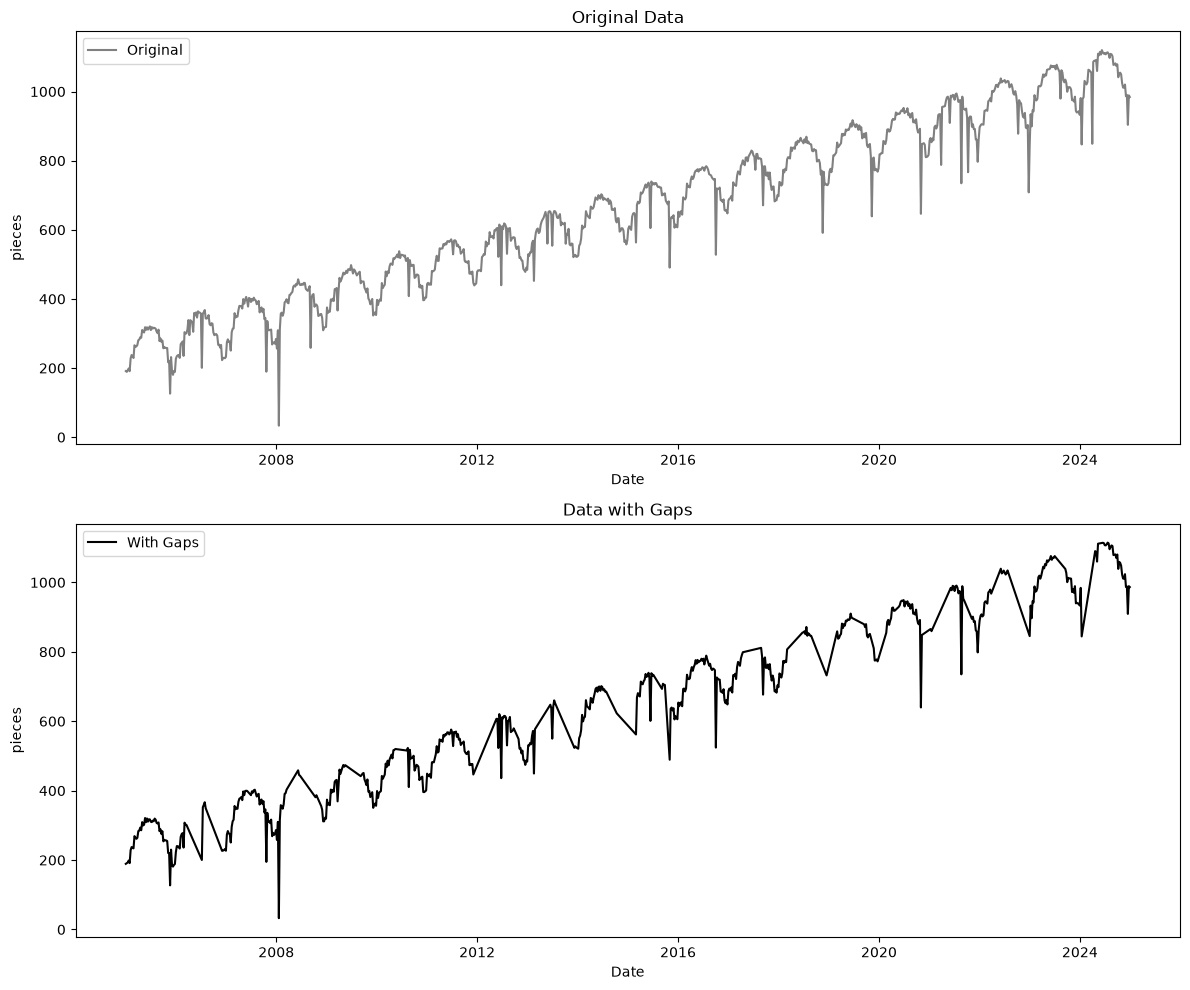

In [14]:
# Funktion plot_production_data definieren 
def plot_production_data(
    df,                     # DataFrame mit den Produktionsdaten
    orig_data_column,       # Name der Spalte mit den Originaldaten ("pieces")
    gap_column,             # Name der Spalte mit den Daten, die Lücken enthalten ("pieces_gaps")
    imp_column=None,        # Optionaer Name einer Spalte ("pieces_imputed")
):
    fig, axes = plt.subplots(
        3 if imp_column else 2, 1, figsize=(12, 10)
    )

    # Original data
    sns.lineplot(
        x=df.index, y=df[orig_data_column],
        ax=axes[0], color="grey", label="Original"
    )
    axes[0].set_title("Original Data")
    axes[0].set_ylabel("pieces")

    # With gaps
    sns.lineplot(
        x=df.index, y=df[gap_column],
        ax=axes[1], color="black", label="With Gaps"
    )
    axes[1].set_title("Data with Gaps")
    axes[1].set_ylabel("pieces")

    # Imputed data (if provided)
    if imp_column is not None:
        dff = df[[gap_column, imp_column]].copy()
        dff.loc[~df[gap_column].isna(), imp_column] = None

        sns.lineplot(
            x=dff.index, y=dff[imp_column],
            ax=axes[2], color="blue", label="Imputed"
        )
        axes[2].set_title("Imputed Data")
        axes[2].set_ylabel("pieces")

    plt.tight_layout()
    plt.show()


# Aufruf der Funktion plot_production_data mit den entsprechenden Spaltennamen
plot_production_data(df, "pieces", "pieces_gaps")

# Smooth the pieces_gaps

In [ ]:
# Glättet die Produktionsdaten mit einem gleitenden Mittelwert.
df["pieces_mean"] = (
    df["pieces_gaps"]
    .rolling(window=7, center=True, min_periods=2)  # Window 7, Reduziert kurzfristige Schwankungen, behält aber langfristigen Trend und saisonale Schwankungen bei.
    .mean()
)

# Glättet die Produktionsdaten mit einem gleitenden Median.
df["pieces_median"] = (
    df["pieces_gaps"]
    .rolling(window=7, center=True, min_periods=2)  # Window 7, Reduziert kurzfristige Schwankungen, behält aber langfristigen Trend und saisonale Schwankungen bei.
    .median()
)

# Erhält die ursprünglichen Datenlücken in beiden Ergebnissen.
df.loc[
    df["pieces_gaps"].isna(),
    ["pieces_mean", "pieces_median"]
] = float("nan")

* Median oder Mittelwert?:
Mittelwert = Summe aller Werte / Anzahl der Werte.
Median = Sortiert die Werte und nimmt den mittleren Wert.

-> Median ist die bessere Wahl, da einzelne extreme Ausreißer weniger Einfluss haben.


Ergänzung:
Es wurde window 7 gewählt, um kurzzeitige Ausreißer auszufiltern, aber den langfristigen Trend sowie saisonale Schwankungen beizubehalten.

Durch min_periods=2 entstehen am 12.10.2014 und 16.12.2018 zwei neue Lücken, da nur ein Wochenwert vorhanden ist.

# Visualize the results using seaborn

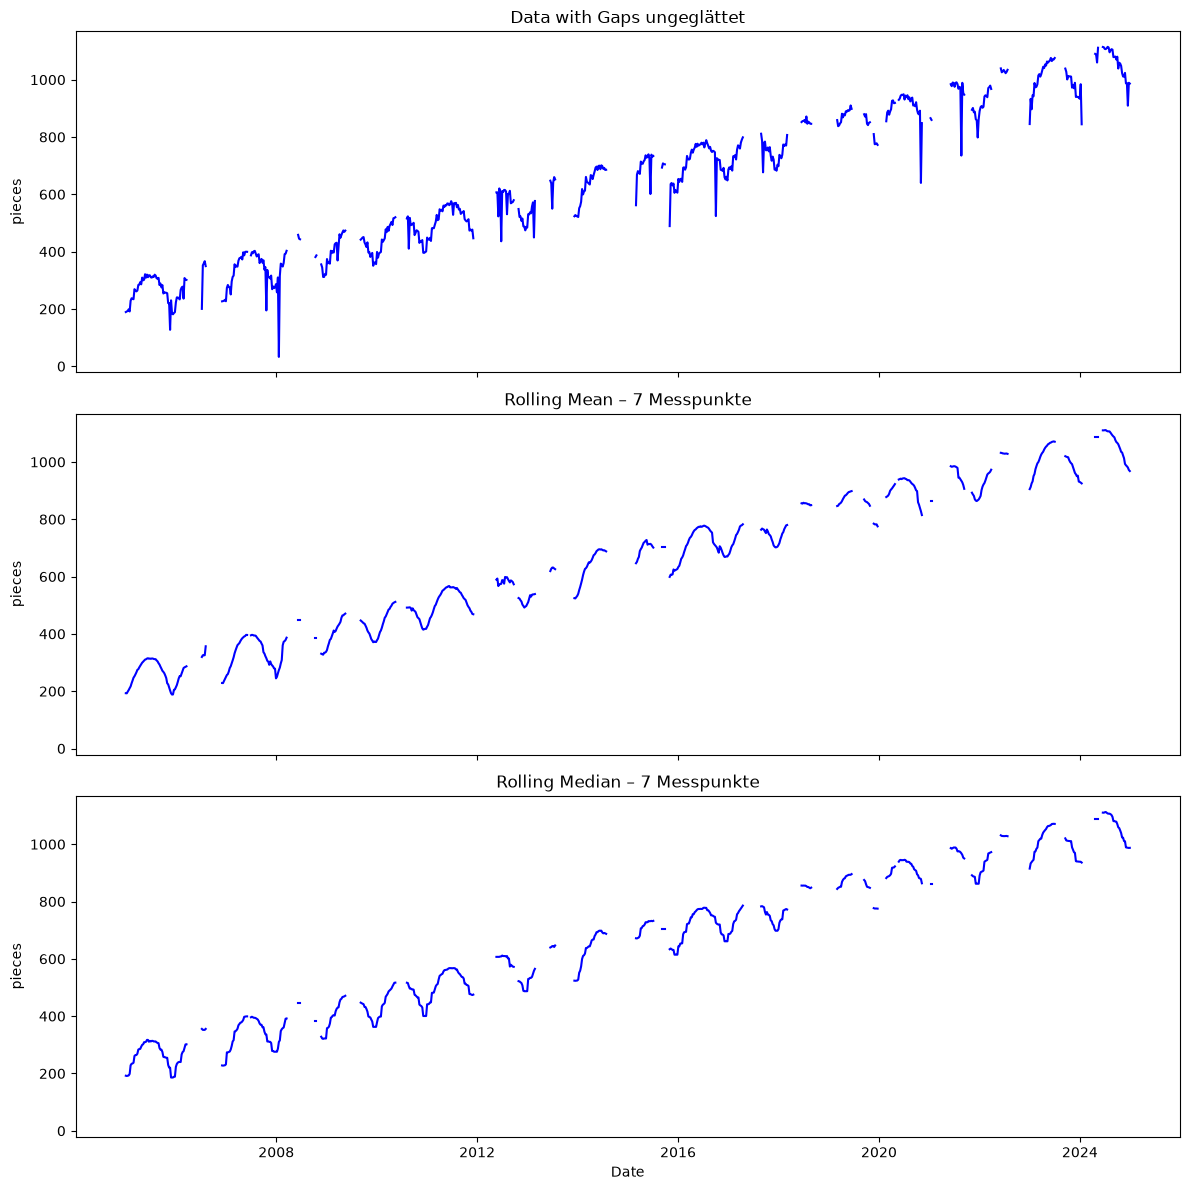

In [15]:
fig, axes = plt.subplots(
    3, 1, figsize=(12, 12), sharex=True, sharey=True
    )

columns = ["pieces_gaps", "pieces_mean", "pieces_median"]
titles = ["Data with Gaps ungeglättet", "Rolling Mean – 7 Messpunkte", "Rolling Median – 7 Messpunkte"]

for ax, column, title in zip(axes, columns, titles):

    # Jede Datenlücke beginnt einen neuen Abschnitt.
    groups = df[column].isna().cumsum()

    # Zeichnet die vorhandenen Werte abschnittsweise.
    for _, segment in df.groupby(groups):
        segment = segment.dropna(subset=[column])

        sns.lineplot(
            x=segment.index,
            y=segment[column],
            ax=ax,
            color="blue",
            estimator=None
        )

    ax.set_title(title)
    ax.set_ylabel("pieces")

axes[2].set_xlabel("Date")
plt.tight_layout()
plt.show()

ipynb exportiert als html mit:

uv run jupyter nbconvert --to html "Tasks/11 Self study - Session 2/Exercise_11.1.ipynb"